# Project — TGV punctuality by route — *Régularité mensuelle TGV par liaisons*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐ easy

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- Which routes are the least punctual, and is it getting better or worse over time?
- What share of delays comes from external causes vs infrastructure vs rolling stock?
- Do long routes have more delays, or just longer ones?


---
## 1 · Context & provenance

*TODO — complete this card before writing any analysis.*

| Field | Your answer |
|---|---|
| **Business question** | On French TGV routes (Jan 2021 – Sep 2026), are long routes late **more often** (share of trains arriving late) or late **by more minutes** when they are late (mean delay of late trains)? Answering this tells an operator or the regulator (AQST) whether punctuality efforts on long routes should aim at **reducing the number of delays** or **shortening them**. |
| **Source** | SNCF open-data portal (ressources.data.sncf.com), dataset `regularite-mensuelle-tgv-aqst` |
| **Dataset page / API docs** | https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/ |
| **Collected by / when** | Sarah BENADDAD Marion GOMES DE SOUSA Farida SAID · 2026-11-04 |
| **Collection method** | REST API (Opendatasoft Explore v2.1), paginated 100 rows/page, cached with `requests-cache` (see Section 3) |
| **Filters applied** | `WHERE = "date >= date'2021-01-01'"`, `ORDER_BY = "date"` → 8,395 rows (= `total_count` reported by the API, nothing truncated), months 2021-01 to 2026-09. No column filter at collection. |
| **Licence / constraints** | Open Database License (ODbL) — attribution required, derived databases must stay under ODbL |
| **Unit of observation** | One row = one route (`gare_depart` → `gare_arrivee`) × one `service` (National / International) × one month (`date`). Checked in Section 3: no duplicate on (`date`, `service`, `gare_depart`, `gare_arrivee`); 42 route-months appear twice, once per service. |
| **Known limitations** | (1) **"Late" depends on trip length** (AQST composite definition): late = ≥ 5 min if trip < 1h30, ≥ 10 min if 1h30–3h, ≥ 15 min if > 3h. Long routes are therefore *less likely* to be counted late by construction — this directly biases our "more often late" comparison. (2) **Monthly aggregates only**: no train-level data, no median or distribution; `retard_moyen_*` are already means, so they must be weighted by number of trains when aggregated. (3) **A train can count in several routes**: rows cannot be summed to get a global or per-axis figure (SNCF warning). (4) **Delays rounded down to the minute**. (5) **COVID in early 2021** (curfew, April lockdown): atypical volumes and delays in H1 2021. (6) **Route length** only as `duree_moyenne` (mean travel time), not distance. (7) **Snapshot**: data as published on 2026-10-02, SNCF can revise past months; pre-2021 data excluded on purpose.(8) **Service split anomaly**: in 2025-07 to 2025-09 only, 14 domestic routes appear twice (once `National`, once `International`). Handled in Section 4.1. |


---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [1]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [2]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30

BASE_URL = "https://ressources.data.sncf.com"
DATASET_ID = "regularite-mensuelle-tgv-aqst"
WHERE = "date >= date'2021-01-01'"
ORDER_BY = "date"
MAX_ROWS = 10_000
PAUSE_S = 0.5

In [3]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    2.1.4
numpy     1.26.4
seaborn   0.12.2
pandera   0.35.0
requests  2.31.0


In [4]:
# Write requirements.txt from the packages this notebook imports
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==2.1.4
numpy==1.26.4
matplotlib==3.8.0
seaborn==0.12.2
pandera==0.35.0
pyarrow==14.0.2
requests==2.31.0
requests-cache==1.3.3



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [5]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [6]:
def collect_ods(base_url, dataset_id, where=None, order_by=None, max_rows=MAX_ROWS, use_export=False):
    """Opendatasoft Explore API v2.1. Offset pagination, 100 rows per page.
    The API refuses offset + limit > 10,000: above that, filter with `where` or use the export endpoint."""
    url = f"{base_url}/api/explore/v2.1/catalog/datasets/{dataset_id}"
    params = {k: v for k, v in {"where": where, "order_by": order_by}.items() if v}
    if use_export:                                   # one call, no row cap, returns a JSON list
        r = get(f"{url}/exports/json", params=params)
        return r.json()[:max_rows]
    rows, offset, limit = [], 0, 100
    while offset < min(max_rows, 10_000):
        r = get(f"{url}/records", params={**params, "limit": limit, "offset": offset})
        page = r.json()
        if offset == 0:
            print(f"API reports {page['total_count']:,} matching rows")
        rows += page["results"]
        if len(page["results"]) < limit:             # last page
            break
        offset += limit
    return rows[:max_rows]

In [7]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_ods(BASE_URL, DATASET_ID, where=WHERE, order_by=ORDER_BY)
print(f"collected {len(raw_rows):,} rows at {collected_at}")

API reports 8,395 matching rows
collected 8,395 rows at 2026-11-05T13:41:30+00:00


### 3.3 Flatten, save raw Parquet + README

In [8]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [9]:
# --- ajout groupe : check de la période collectée ---
# avec le WHERE on doit avoir de 2021-01 jusqu'au dernier mois publié
print(df_raw["date"].min(), "→", df_raw["date"].max())

2021-01 → 2026-09


In [10]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(8395, 26)


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_annulation,commentaire_annulation,nb_train_depart_retard,retard_moyen_depart,...,nb_train_retard_sup_15,retard_moyen_trains_retard_sup15,nb_train_retard_sup_30,nb_train_retard_sup_60,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
0,2021-01,International,BARCELONA,PARIS LYON,401,30,0,None,0,0.000000,...,2,18.333333,0,0,50.000000,0.000000,0.000000,0.000000,0.000000,50.0
1,2021-01,International,LAUSANNE,PARIS LYON,226,98,1,None,85,3.169412,...,6,33.141667,3,0,33.333333,16.666667,0.000000,16.666667,33.333333,0.0
2,2021-01,International,PARIS LYON,BARCELONA,399,31,0,None,0,0.000000,...,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
3,2021-01,International,PARIS LYON,ITALIE,425,62,1,None,1,1.816667,...,4,57.125000,3,1,0.000000,25.000000,25.000000,25.000000,0.000000,25.0
4,2021-01,International,ZURICH,PARIS LYON,244,102,0,None,45,1.745185,...,13,60.610256,9,4,30.769231,23.076923,23.076923,15.384615,7.692308,0.0


In [11]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
commentaire_annulation,object,1.0,0
commentaire_retards_depart,object,1.0,0
commentaires_retard_arrivee,object,1.0,0
date,object,0.0,69
retard_moyen_tous_trains_arrivee,float64,0.0,8291
prct_cause_gestion_gare,float64,0.0,2140
prct_cause_materiel_roulant,float64,0.0,2363
prct_cause_gestion_trafic,float64,0.0,2254
prct_cause_infra,float64,0.0,2240
prct_cause_externe,float64,0.0,2478


In [12]:
# --- ajout groupe : check de l'unité d'observation ---
# au début on pensait 1 ligne = 1 liaison x 1 mois, mais y'a des doublons sans le service
key_sans_service = ["date", "gare_depart", "gare_arrivee"]
key = ["date", "service", "gare_depart", "gare_arrivee"]
print("doublons sans service :", df_raw.duplicated(key_sans_service).sum())   # 42
print("doublons avec service :", df_raw.duplicated(key).sum())                # 0 -> c'est ça la vraie clé

# les 42 c'est des paires National / International, que sur juillet-sept 2025 (14 liaisons/mois)
dups = df_raw[df_raw.duplicated(key_sans_service, keep=False)]
print(dups.groupby(["date", "service"]).size())

# et ces 14 liaisons sont en National tout le reste du temps -> anomalie de publication
# on décide quoi en faire en 4.1
liaisons = dups[["gare_depart", "gare_arrivee"]].drop_duplicates()
print(df_raw.merge(liaisons, on=["gare_depart", "gare_arrivee"])["service"].value_counts())

doublons sans service : 42
doublons avec service : 0
date     service      
2025-07  International    14
         National         14
2025-08  International    14
         National         14
2025-09  International    14
         National         14
dtype: int64
service
National         966
International     42
Name: count, dtype: int64


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): `date`, `service`, `gare_depart`, `gare_arrivee`, `duree_moyenne`, `nb_train_prevu`, `nb_annulation`, `nb_train_retard_arrivee`, `retard_moyen_arrivee` and the `prct_cause_*` columns.

In [13]:
# TODO: select the columns you keep, then write the contract
# KEEP = list(df_raw.columns)          # TODO: replace by your selection (and log it as a decision)

# colonnes gardées pour notre question (longs trajets = + de retards ou retards + longs ?)
KEEP = [
    # clé
    "date", "service", "gare_depart", "gare_arrivee",
    # longueur du trajet (en min, pas de distance dispo)
    "duree_moyenne",
    # fréquence -> % en retard = retard / (prévus - annulés)
    "nb_train_prevu", "nb_annulation", "nb_train_retard_arrivee",
    # ampleur -> retard moyen des trains EN RETARD seulement
    # (pas tous_trains, ça mélange fréquence et ampleur)
    "retard_moyen_arrivee",
    # gros retards + pour tester les seuils AQST 5/10/15 min en partie 4
    "nb_train_retard_sup_15", "nb_train_retard_sup_30", "nb_train_retard_sup_60",
]
# virés : départ (l'AQST regarde l'arrivée), causes (= question 2 pas la nôtre),
# commentaires (texte libre), retard_moyen_trains_retard_sup15 (redondant)

df_sel = df_raw[KEEP].copy()

#schema = None                        # TODO: replace None by pa.DataFrameSchema({...}, strict=True)

# pas de nullable=True : 0% de manquants sur les colonnes gardées (cf overview)
schema = pa.DataFrameSchema(
    {
        "date": pa.Column(str, pa.Check.str_matches(r"^\d{4}-\d{2}$"), nullable=False),   # format AAAA-MM
        "service": pa.Column(str, pa.Check.isin(["National", "International"]), nullable=False),
        "gare_depart": pa.Column(str, pa.Check.str_length(min_value=1), nullable=False),
        "gare_arrivee": pa.Column(str, pa.Check.str_length(min_value=1), nullable=False),
        "duree_moyenne": pa.Column(int, pa.Check.in_range(1, 600), nullable=False),        # trajet TGV < 10h
        "nb_train_prevu": pa.Column(int, pa.Check.ge(0), nullable=False),                 # nb de trains >= 0
        "nb_annulation": pa.Column(int, pa.Check.ge(0), nullable=False),
        "nb_train_retard_arrivee": pa.Column(int, pa.Check.ge(0), nullable=False),
        "retard_moyen_arrivee": pa.Column(float, pa.Check.ge(0), nullable=False),         # retard moyen >= 0
        "nb_train_retard_sup_15": pa.Column(int, pa.Check.ge(0), nullable=False),
        "nb_train_retard_sup_30": pa.Column(int, pa.Check.ge(0), nullable=False),
        "nb_train_retard_sup_60": pa.Column(int, pa.Check.ge(0), nullable=False),
    },
    checks=[
        # pas plus d'annulations que de trains prévus
        pa.Check(lambda d: d["nb_annulation"] <= d["nb_train_prevu"], name="annul_le_prevu"),
        # en retard <= trains qui ont vraiment roulé
        pa.Check(lambda d: d["nb_train_retard_arrivee"] <= d["nb_train_prevu"] - d["nb_annulation"],
                 name="retard_le_circules"),
        # paliers emboîtés : +60 min <= +30 <= +15
        pa.Check(lambda d: (d["nb_train_retard_sup_60"] <= d["nb_train_retard_sup_30"])
                         & (d["nb_train_retard_sup_30"] <= d["nb_train_retard_sup_15"]),
                 name="paliers_emboites"),
        # seuil AQST max = 15 min, donc un train à +15 est forcément compté en retard
        pa.Check(lambda d: d["nb_train_retard_sup_15"] <= d["nb_train_retard_arrivee"],
                 name="sup15_le_retard"),
    ],
    unique=["date", "service", "gare_depart", "gare_arrivee"],   # clé validée en 3.3
    strict=True,
)

if schema is not None:
    try:
        schema.validate(df_sel, lazy=True)
        print("✅ raw data passes the contract")
    except pa.errors.SchemaErrors as err:
        fails = err.failure_cases
        print(f"❌ {len(fails)} violations")
        display(fails.groupby(["column", "check"]).size().rename("n").reset_index())

❌ 4303 violations


,column,check,n
0,date,paliers_emboites,355
1,duree_moyenne,paliers_emboites,355
2,gare_arrivee,paliers_emboites,355
3,gare_depart,paliers_emboites,355
4,nb_annulation,paliers_emboites,355
5,nb_train_prevu,paliers_emboites,355
6,nb_train_retard_arrivee,paliers_emboites,355
7,nb_train_retard_sup_15,paliers_emboites,355
8,nb_train_retard_sup_30,greater_than_or_equal_to(0),43
9,nb_train_retard_sup_30,paliers_emboites,355


In [14]:
# --- ajout groupe : résumé lisible des violations (en lignes, pas en cellules) ---
# les checks multi-colonnes comptent 1 violation par colonne -> on compte les lignes uniques
fails.groupby("check")["index"].nunique().rename("n_lignes")

check
greater_than_or_equal_to(0)     43
paliers_emboites               355
Name: n_lignes, dtype: int64

---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Missing months for some routes (COVID 2020, strikes): is that MNAR? Can you compare years fairly?
- Station names that change spelling over time: duplicates in disguise. Build a mapping and log it.
- Do the `prct_cause_*` shares add up to 100%? Check row by row.
- Means of means: `retard_moyen_arrivee` is already an average — weight by number of trains when aggregating.

In [15]:
decisions = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=n_rows, decision=decision, why=why))

df = df_sel.copy()

In [16]:
# --- ajout groupe : on log la sélection de colonnes faite en 3.4 ---
log("26 → 12 columns", "column selection", len(df_raw),
    "keep key, duree_moyenne, arrival counts, retard_moyen_arrivee, sup_15/30/60",
    "departure, causes and comments don't serve our question; "
    "retard_moyen_tous_trains mixes frequency and magnitude")

### 4.1 Duplicates

In [17]:
n_exact = int(df.astype(str).duplicated().sum())    # astype(str): some columns may hold dicts
print("exact duplicate rows:", n_exact)

# --- ajout groupe ---
# doublons exacts
if n_exact > 0:
    df = df.drop_duplicates()
log("all", "exact duplicate rows", n_exact,
    "drop" if n_exact else "nothing to do", "an identical row adds no information")

# quasi-doublons : même liaison même mois publiée en National ET International (cf 3.3)
key_sans_service = ["date", "gare_depart", "gare_arrivee"]
anom = df.duplicated(key_sans_service, keep=False) & (df["service"] == "International")
print("lignes International en double :", anom.sum())   # 42 attendu
df = df[~anom].copy()
log("service", "same route-month published as National AND International (2025-07 to 09 only)",
    int(anom.sum()), "drop the International row",
    "these 14 routes are National every other month; keeping both counts the route twice")
print("doublons restants sans service :", df.duplicated(key_sans_service).sum())   # doit faire 0

exact duplicate rows: 0
lignes International en double : 42
doublons restants sans service : 0


In [18]:
# --- ajout groupe : noms de gares presque identiques ? (ex: changement d'orthographe) ---
import difflib
gares = sorted(set(df["gare_depart"]) | set(df["gare_arrivee"]))
print(len(gares), "gares différentes")
for g in gares:
    proches = [m for m in difflib.get_close_matches(g, gares, n=4, cutoff=0.8) if m != g]
    if proches:
        print(g, "→", proches)

58 gares différentes


In [19]:
# --- ajout groupe : vérif à l'oeil des noms de gares ---
# pour chaque gare : nb de lignes + 1er et dernier mois où elle apparaît
# si une gare disparaît pile quand une autre apparaît -> sûrement un renommage
long = pd.concat([
    df[["date", "gare_depart"]].rename(columns={"gare_depart": "gare"}),
    df[["date", "gare_arrivee"]].rename(columns={"gare_arrivee": "gare"}),
])
resume_gares = (long.groupby("gare")["date"]
                .agg(n_lignes="size", premier_mois="min", dernier_mois="max")
                .sort_index())
pd.set_option("display.max_rows", 100)
resume_gares

,n_lignes,premier_mois,dernier_mois
gare,,,
AIX EN PROVENCE TGV,138,2021-01,2026-09
ANGERS SAINT LAUD,138,2021-01,2026-09
ANGOULEME,138,2021-01,2026-09
ANNECY,138,2021-01,2026-09
ARRAS,138,2021-01,2026-09
AVIGNON TGV,138,2021-01,2026-09
BARCELONA,138,2021-01,2026-09
BELLEGARDE (AIN),138,2021-01,2026-09
BESANCON FRANCHE COMTE TGV,138,2021-01,2026-09


In [20]:
# relu à la main : pas de renommage
# MADRID = vraie liaison temporaire (avr-déc 2022), aucune gare n'apparaît à sa place
# rien trouvé à cutoff 0.8 -> noms de gares stables sur la période
log("gare_depart / gare_arrivee", "near-duplicate station names (spelling changes)", 0,
    "nothing to do", f"no pair of names above 0.8 similarity among {len(gares)} stations")

### 4.2 Impossible values

In [21]:
# TODO: for each numeric column, what is physically or logically impossible? Count, decide, log.
df.describe().T

# --- ajout groupe : une règle "impossible" par colonne numérique, on compte ---
circules = df["nb_train_prevu"] - df["nb_annulation"]
regles = {
    "duree_moyenne <= 0":                         df["duree_moyenne"] <= 0,
    "nb_train_prevu < 0":                         df["nb_train_prevu"] < 0,
    "nb_annulation < 0":                          df["nb_annulation"] < 0,
    "nb_annulation > nb_train_prevu":             df["nb_annulation"] > df["nb_train_prevu"],
    "nb_train_retard_arrivee < 0":                df["nb_train_retard_arrivee"] < 0,
    "nb_train_retard_arrivee > trains circulés":  df["nb_train_retard_arrivee"] > circules,
    "retard_moyen_arrivee < 0":                   df["retard_moyen_arrivee"] < 0,
    "retard_moyen > 0 sans train en retard":      (df["nb_train_retard_arrivee"] == 0) & (df["retard_moyen_arrivee"] > 0),
    "sup_15 / sup_30 / sup_60 < 0":               (df[["nb_train_retard_sup_15", "nb_train_retard_sup_30",
                                                       "nb_train_retard_sup_60"]] < 0).any(axis=1),
}
impossibles = pd.Series({r: int(m.sum()) for r, m in regles.items()}, name="n_lignes")
display(impossibles.to_frame())

# tout est à 0 sauf les paliers -> rien à faire sur ces colonnes, on log
log("duree_moyenne, nb_train_prevu, nb_annulation, nb_train_retard_arrivee, retard_moyen_arrivee",
    "impossible values (negative, more cancellations than planned, more late than run...)", 0,
    "nothing to do", "every rule above returns 0 rows")

display(df.describe().T)

,n_lignes
duree_moyenne <= 0,0
nb_train_prevu < 0,0
nb_annulation < 0,0
nb_annulation > nb_train_prevu,0
nb_train_retard_arrivee < 0,0
nb_train_retard_arrivee > trains circulés,0
retard_moyen_arrivee < 0,0
retard_moyen > 0 sans train en retard,0
sup_15 / sup_30 / sup_60 < 0,43


,count,mean,std,min,25%,50%,75%,max
duree_moyenne,8353.0,172.959535,88.573142,45.0,99.000000,164.000000,227.000000,564.0
nb_train_prevu,8353.0,295.228541,192.500884,2.0,168.000000,243.000000,405.000000,1104.0
nb_annulation,8353.0,6.154555,19.007168,0.0,0.000000,1.000000,4.000000,297.0
nb_train_retard_arrivee,8353.0,41.943374,33.882273,0.0,18.000000,33.000000,57.000000,376.0
retard_moyen_arrivee,8353.0,37.421496,15.421386,0.0,27.942262,35.595238,44.761632,299.6
nb_train_retard_sup_15,8353.0,31.051479,25.483988,0.0,13.000000,25.000000,42.000000,312.0
nb_train_retard_sup_30,8353.0,14.900515,14.198883,-44.0,5.000000,11.000000,20.000000,202.0
nb_train_retard_sup_60,8353.0,6.461870,7.116842,0.0,2.000000,4.000000,9.000000,77.0


In [22]:
# --- décision : T1 2025 publié de travers pour les paliers (sup_30 à 0 ou négatif, sup_60 > sup_30) ---
# c'est tout le trimestre (presque toutes les liaisons) -> on met les 3 paliers en NaN pour tout T1 2025
# on garde les lignes : retard_arrivee et retard_moyen_arrivee sont ok
t1_2025 = df["date"].isin(["2025-01", "2025-02", "2025-03"])
paliers = ["nb_train_retard_sup_15", "nb_train_retard_sup_30", "nb_train_retard_sup_60"]
print("lignes du T1 2025 :", t1_2025.sum())
df.loc[t1_2025, paliers] = np.nan
log("nb_train_retard_sup_15/30/60", "impossible values: sup_30 negative or 0, sup_60 > sup_30 "
    "(355 rows, all in 2025-01 to 2025-03)", int(t1_2025.sum()),
    "set the 3 tiers to NaN for the whole quarter, keep the rows",
    "systematic publication error on one quarter, not random; main columns are valid so rows are kept")

# check : plus aucun palier incohérent
non_emb = ((df["nb_train_retard_sup_60"] > df["nb_train_retard_sup_30"])
           | (df["nb_train_retard_sup_30"] > df["nb_train_retard_sup_15"]))
print("paliers pas emboîtés après correction :", non_emb.sum())   # doit faire 0

lignes du T1 2025 : 363
paliers pas emboîtés après correction : 0


In [23]:
# --- ajout groupe : les autres colonnes du T1 2025 sont-elles fiables ? ---
# si tout le traitement du trimestre était cassé, on verrait un saut sur ces mois
# taux de retard et retard moyen pondérés par le nb de trains (pas de moyenne de moyennes)
d = df.assign(circules=df["nb_train_prevu"] - df["nb_annulation"])
d["minutes_retard"] = d["retard_moyen_arrivee"] * d["nb_train_retard_arrivee"]
par_mois = d.groupby("date").agg(circules=("circules", "sum"),
                                 en_retard=("nb_train_retard_arrivee", "sum"),
                                 minutes=("minutes_retard", "sum"),
                                 duree=("duree_moyenne", "mean"))
par_mois["taux_retard_%"] = (100 * par_mois["en_retard"] / par_mois["circules"]).round(1)
par_mois["retard_moyen_min"] = (par_mois["minutes"] / par_mois["en_retard"]).round(1)

# on compare T1 2025 avec les mois autour et le T1 des autres années
mois = ["2024-01", "2024-02", "2024-03", "2024-10", "2024-11", "2024-12",
        "2025-01", "2025-02", "2025-03", "2025-04", "2025-05", "2025-06",
        "2026-01", "2026-02", "2026-03"]
par_mois.loc[mois, ["circules", "taux_retard_%", "retard_moyen_min", "duree"]]

,circules,taux_retard_%,retard_moyen_min,duree
date,,,,
2024-01,37035,15.8,34.0,172.446281
2024-02,33553,12.1,29.5,172.148760
2024-03,37013,13.4,36.1,174.107438
2024-10,37902,11.7,31.1,174.280992
2024-11,33815,16.5,35.1,176.809917
2024-12,37028,13.7,34.8,172.743802
2025-01,37370,14.5,35.6,173.314050
2025-02,33243,12.8,35.1,173.677686
2025-03,37007,11.5,37.9,174.264463


In [24]:
# T1 2025 dans la même zone que les mois autour et que T1 2024 / T1 2026 (pas de saut)
# -> le problème est limité aux paliers, les autres colonnes sont gardées
log("nb_train_retard_arrivee / retard_moyen_arrivee / duree_moyenne (2025-01 to 03)",
    "could the T1 2025 publication error affect other columns?", int(t1_2025.sum()),
    "keep as is",
    "monthly late rate, weighted mean delay and duration of T1 2025 are in the range of "
    "neighbouring months and of T1 2024 / T1 2026; no jump")

### 4.3 Missingness — mechanism before method

In [25]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].rename("share_missing").to_frame()
miss["flag"] = np.where(miss.share_missing > MAX_MISSING_SHARE, "⚠️ high", "")
miss

,share_missing,flag
nb_train_retard_sup_15,0.043457,
nb_train_retard_sup_30,0.043457,
nb_train_retard_sup_60,0.043457,


In [26]:
# TODO: for the 2–3 most important columns with missing values, test whether missingness
# depends on another observed column (MAR) — e.g.
# df.assign(m=df["<col>"].isna()).groupby("<other col>")["m"].mean()
# Then name the mechanism (MCAR / MAR / MNAR), decide, log.

In [27]:
# --- ajout groupe : manquants n°1, les NaN des paliers ---
# test MAR : est-ce que le manque dépend d'une autre colonne observée (ici la date) ?
m = df["nb_train_retard_sup_30"].isna()
taux_par_mois = df.assign(m=m).groupby("date")["m"].mean()
print(taux_par_mois[taux_par_mois > 0])   # attendu : 100% sur 2025-01/02/03, 0% ailleurs

# --- ajout groupe : manquants n°2, les mois absents (pas des NaN, des lignes qui n'existent pas) ---
# on construit la grille complète liaison x mois et on regarde ce qui manque
routes = df[["service", "gare_depart", "gare_arrivee"]].drop_duplicates()
tous_mois = pd.DataFrame({"date": sorted(df["date"].unique())})
grille = routes.merge(tous_mois, how="cross")
absents = (grille.merge(df[["service", "gare_depart", "gare_arrivee", "date"]],
                        how="left", indicator=True)
                 .query("_merge == 'left_only'"))
print("liaisons x mois absents :", len(absents), "sur", len(grille))
absents.groupby(["service", "gare_depart", "gare_arrivee"])["date"].agg(["size", "min", "max"])

date
2025-01    1.0
2025-02    1.0
2025-03    1.0
Name: m, dtype: float64
liaisons x mois absents : 341 sur 8694


size      min  \
service       gare_depart          gare_arrivee                          
International BARCELONA            PARIS LYON              12  2025-10   
              ITALIE               PARIS LYON               4  2023-10   
              MADRID               MARSEILLE ST CHARLES    60  2021-01   
              MARSEILLE ST CHARLES MADRID                  60  2021-01   
              PARIS LYON           BARCELONA               12  2025-10   
                                   ITALIE                   4  2023-10   
                                   ZURICH                   1  2022-06   
              ZURICH               PARIS LYON               1  2022-06   
National      BARCELONA            PARIS LYON              57  2021-01   
              BORDEAUX ST JEAN     TOURCOING                2  2021-04   
              MARSEILLE ST CHARLES TOURCOING                1  2021-04   
              PARIS LYON           BARCELONA               57  2021-01   
              TOURCOING            BORDEAUX ST JEAN         2  2021-04   
                                   MARSEILLE ST CHARLES    68  2021-01   

                                                             max  
service       gare_depart          gare_arrivee                   
International BARCELONA            PARIS LYON            2026-09  
              ITALIE               PARIS LYON            2024-06  
              MADRID               MARSEILLE ST CHARLES  2026-09  
              MARSEILLE ST CHARLES MADRID                2026-09  
              PARIS LYON           BARCELONA             2026-09  
                                   ITALIE                2024-06  
                                   ZURICH                2022-06  
              ZURICH               PARIS LYON            2022-06  
National      BARCELONA            PARIS LYON            2025-09  
              BORDEAUX ST JEAN     TOURCOING             2022-11  
              MARSEILLE ST CHARLES TOURCOING             2021-04  
              PARIS LYON           BARCELONA             2025-09  
              TOURCOING            BORDEAUX ST JEAN      2022-11  
                                   MARSEILLE ST CHARLES  2026-09

In [28]:
# hypothèse : saisonnalité (la SNCF adapte l'offre à la demande)
# si c'est vrai -> les mois absents reviennent aux mêmes mois de l'année, année après année
absents["annee"] = absents["date"].str[:4]
absents["mois"] = absents["date"].str[5:7]
display(pd.crosstab([absents["gare_depart"], absents["gare_arrivee"]], absents["annee"]))
display(pd.crosstab([absents["gare_depart"], absents["gare_arrivee"]], absents["mois"]))

annee                                      2021  2022  2023  2024  2025  2026
gare_depart          gare_arrivee                                            
BARCELONA            PARIS LYON              12    12    12    12    12     9
BORDEAUX ST JEAN     TOURCOING                1     1     0     0     0     0
ITALIE               PARIS LYON               0     0     3     1     0     0
MADRID               MARSEILLE ST CHARLES    12     3    12    12    12     9
MARSEILLE ST CHARLES MADRID                  12     3    12    12    12     9
                     TOURCOING                1     0     0     0     0     0
PARIS LYON           BARCELONA               12    12    12    12    12     9
                     ITALIE                   0     0     3     1     0     0
                     ZURICH                   0     1     0     0     0     0
TOURCOING            BORDEAUX ST JEAN         1     1     0     0     0     0
                     MARSEILLE ST CHARLES    12    11    12    12    12     9
ZURICH               PARIS LYON               0     1     0     0     0     0

mois                                       01  02  03  04  05  06  07  08  09  \
gare_depart          gare_arrivee                                               
BARCELONA            PARIS LYON             6   6   6   6   6   6   6   6   6   
BORDEAUX ST JEAN     TOURCOING              0   0   0   1   0   0   0   0   0   
ITALIE               PARIS LYON             0   0   0   0   0   1   0   0   0   
MADRID               MARSEILLE ST CHARLES   6   6   6   5   5   5   5   5   5   
MARSEILLE ST CHARLES MADRID                 6   6   6   5   5   5   5   5   5   
                     TOURCOING              0   0   0   1   0   0   0   0   0   
PARIS LYON           BARCELONA              6   6   6   6   6   6   6   6   6   
                     ITALIE                 0   0   0   0   0   1   0   0   0   
                     ZURICH                 0   0   0   0   0   1   0   0   0   
TOURCOING            BORDEAUX ST JEAN       0   0   0   1   0   0   0   0   0   
                     MARSEILLE ST CHARLES   6   6   6   6   6   6   6   5   6   
ZURICH               PARIS LYON             0   0   0   0   0   1   0   0   0   

mois                                       10  11  12  
gare_depart          gare_arrivee                      
BARCELONA            PARIS LYON             5   5   5  
BORDEAUX ST JEAN     TOURCOING              0   1   0  
ITALIE               PARIS LYON             1   1   1  
MADRID               MARSEILLE ST CHARLES   4   4   4  
MARSEILLE ST CHARLES MADRID                 4   4   4  
                     TOURCOING              0   0   0  
PARIS LYON           BARCELONA              5   5   5  
                     ITALIE                 1   1   1  
                     ZURICH                 0   0   0  
TOURCOING            BORDEAUX ST JEAN       0   1   0  
                     MARSEILLE ST CHARLES   5   5   5  
ZURICH               PARIS LYON             0   0   0

In [29]:
# manquants n°1 : NaN des paliers = 100% sur T1 2025, 0% ailleurs -> dépend de la date (observée) = MAR
log("nb_train_retard_sup_15/30/60", "missing values (created in 4.2)", int(m.sum()),
    "leave as NaN, no imputation; tiers analysed on other months only",
    "MAR: missingness depends only on date (100% in 2025-01 to 03, 0% elsewhere)")

# manquants n°2 : mois absents -> pas de la saisonnalité (aucun mois qui revient chaque année)
log("service", "Barcelona-Paris route switches from International to National in 2025-10", 69,
    "keep as is; analyse this route without splitting by service",
    "not missing data: same route relabelled, all 69 months are present")
log("route-month (absent rows)", "Madrid-Marseille only operated 2022-04 to 2022-12 (both directions)", 120,
    "keep existing rows, no imputation", "no train ran outside that period, nothing to measure")
log("route-month (absent rows)", "Tourcoing->Marseille published 1 month out of 69 "
    "(reverse Marseille->Tourcoing: 68 months)", 68,
    "keep as is, do not assume every route has a return",
    "structural: some routes are only published one way, return trains run on another branch "
    "and are counted under another route (domain knowledge)")

In [30]:
# --- ajout groupe : preuve que Tourcoing->Marseille n'est publié que dans un sens ---
# Bordeaux<->Tourcoing dans les 2 sens, Marseille->Tourcoing 68 mois, mais Tourcoing->Marseille 1 seul mois
# -> le retour passe par une autre branche (connaissance métier), la ligne isolée est une anomalie de publication

# Tourcoing : dans quels sens apparaît-elle ?
df[(df["gare_depart"] == "TOURCOING") | (df["gare_arrivee"] == "TOURCOING")] \
    .groupby(["gare_depart", "gare_arrivee"]).size()

gare_depart           gare_arrivee        
BORDEAUX ST JEAN      TOURCOING               67
MARSEILLE ST CHARLES  TOURCOING               68
TOURCOING             BORDEAUX ST JEAN        67
                      MARSEILLE ST CHARLES     1
dtype: int64

### 4.4 Outliers — triage, don't delete

In [31]:
# TODO: pick your key numeric column. Use an IQR fence (on a log scale if it is skewed),
# look at the flagged rows, separate errors from real extremes, decide per group, log.

In [32]:

# --- ajout groupe : outliers sur retard_moyen_arrivee (notre mesure d'ampleur) ---
# colonne très asymétrique (75% < 45 min mais max à 300) -> IQR sur le log
# log1p = log(1+x) car il y a des 0
x = np.log1p(df["retard_moyen_arrivee"])
q1, q3 = x.quantile([0.25, 0.75])
bas, haut = q1 - IQR_K * (q3 - q1), q3 + IQR_K * (q3 - q1)
print(f"bornes en minutes : {np.expm1(bas):.1f} → {np.expm1(haut):.1f}")
print("hors bornes :", ((x < bas) | (x > haut)).sum(),
      "| trop hautes :", (x > haut).sum(), "| trop basses :", (x < bas).sum())

cols = ["date", "service", "gare_depart", "gare_arrivee", "duree_moyenne",
        "nb_train_prevu", "nb_train_retard_arrivee", "retard_moyen_arrivee"]

# --- groupe 1 : trop hautes -> vrais incidents ---
# souvent 1-2 trains en retard sur des longs trajets : extrême mais pas faux
haut_flag = x > haut
display(df.loc[haut_flag, cols].sort_values("retard_moyen_arrivee", ascending=False).head(10))
print("hautes avec <= 2 trains en retard :", (haut_flag & (df["nb_train_retard_arrivee"] <= 2)).sum())
log("retard_moyen_arrivee", "high outliers > 90 min (IQR on log scale)", int(haut_flag.sum()),
    "keep; weight by nb_train_retard_arrivee in analysis",
    "real incidents on long routes, often a mean over 1-2 late trains: extreme but not wrong")

# --- groupe 2 : trop basses -> 3 sous-groupes à séparer ---
faux_zero = (df["nb_train_retard_arrivee"] > 0) & (df["retard_moyen_arrivee"] == 0)
vrai_zero = (df["nb_train_retard_arrivee"] == 0) & (df["retard_moyen_arrivee"] == 0)
petits = (x < bas) & (df["retard_moyen_arrivee"] > 0)
print("faux zéros :", faux_zero.sum(), "| vrais zéros :", vrai_zero.sum(), "| petites valeurs > 0 :", petits.sum())

# 2a. faux zéros : des trains en retard mais moyenne = 0 -> impossible = manquant codé en 0
print(df.loc[faux_zero, "date"].value_counts().sort_index())   # concentré sur certains mois ?
df.loc[faux_zero, "retard_moyen_arrivee"] = np.nan
log("retard_moyen_arrivee", "0 while nb_train_retard_arrivee > 0 (disguised missing)", int(faux_zero.sum()),
    "set to NaN", "a mean delay of 0 is impossible when trains were late: 0 fills an empty value")

# 2b. vrais zéros : aucun train en retard -> moyenne 0 logique
log("retard_moyen_arrivee", "0 with no late train", int(vrai_zero.sum()),
    "keep", "logical: no late train, mean delay = 0")

# 2c. petites valeurs : plausibles sur trajets courts (seuil AQST = 5 min si trajet < 1h30)
print("durée médiane des trajets à petites valeurs :", df.loc[petits, "duree_moyenne"].median(), "min")
log("retard_moyen_arrivee", "low outliers > 0 (below IQR fence)", int(petits.sum()),
    "keep", "plausible on short routes: AQST counts a train late from 5 min if trip < 1h30")

bornes en minutes : 13.6 → 90.0
hors bornes : 192 | trop hautes : 45 | trop basses : 147


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_train_retard_arrivee,retard_moyen_arrivee
3345,2023-04,National,TOURCOING,BORDEAUX ST JEAN,300,30,1,299.600000
865,2021-08,National,RENNES,LYON PART DIEU,240,92,1,255.866667
2937,2023-01,National,TOURCOING,BORDEAUX ST JEAN,295,31,2,218.691667
5141,2024-07,National,TOURCOING,BORDEAUX ST JEAN,304,31,5,187.010000
3896,2023-09,National,MARSEILLE ST CHARLES,TOURCOING,291,30,1,160.000000
3209,2023-03,National,TOURCOING,BORDEAUX ST JEAN,300,31,2,157.133333
289,2021-03,International,ZURICH,PARIS LYON,244,88,3,147.716667
4676,2024-03,National,TOURCOING,BORDEAUX ST JEAN,301,31,2,146.700000
7459,2026-02,National,MARSEILLE ST CHARLES,TOURCOING,294,8,2,129.500000
8070,2026-07,National,MARSEILLE ST CHARLES,TOURCOING,286,31,7,128.142857


hautes avec <= 2 trains en retard : 13
faux zéros : 37 | vrais zéros : 75 | petites valeurs > 0 : 35
date
2021-01    1
2021-02    1
2021-03    1
2021-04    2
2021-05    1
2021-06    2
2021-07    2
2021-08    2
2021-09    2
2021-10    1
2021-11    1
2021-12    1
2022-04    1
2022-05    1
2022-06    1
2022-07    1
2022-08    1
2022-09    1
2022-10    1
2022-11    3
2023-06    1
2023-09    2
2024-04    1
2024-05    1
2024-06    1
2025-04    1
2025-05    2
2025-11    1
Name: count, dtype: int64
durée médiane des trajets à petites valeurs : 75.0 min


In [33]:
# faux zéros : pas concentrés dans le temps -> concentrés sur certaines liaisons / service ?
print(df.loc[faux_zero, "service"].value_counts())
df.loc[faux_zero].groupby(["gare_depart", "gare_arrivee"]).size().sort_values(ascending=False).head(10)

service
International    28
National          9
Name: count, dtype: int64


gare_depart         gare_arrivee        
BARCELONA           PARIS LYON              15
MADRID              MARSEILLE ST CHARLES     8
STUTTGART           PARIS EST                4
TOURCOING           BORDEAUX ST JEAN         4
PARIS MONTPARNASSE  ST MALO                  2
ANNECY              PARIS LYON               1
ITALIE              PARIS LYON               1
ST MALO             PARIS MONTPARNASSE       1
TOURS               PARIS MONTPARNASSE       1
dtype: int64

In [34]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,26 → 12 columns,column selection,8395,"keep key, duree_moyenne, arrival counts, retar...","departure, causes and comments don't serve our..."
1,all,exact duplicate rows,0,nothing to do,an identical row adds no information
2,service,same route-month published as National AND Int...,42,drop the International row,these 14 routes are National every other month...
3,gare_depart / gare_arrivee,near-duplicate station names (spelling changes),0,nothing to do,no pair of names above 0.8 similarity among 58...
4,"duree_moyenne, nb_train_prevu, nb_annulation, ...","impossible values (negative, more cancellation...",0,nothing to do,every rule above returns 0 rows
5,nb_train_retard_sup_15/30/60,"impossible values: sup_30 negative or 0, sup_6...",363,"set the 3 tiers to NaN for the whole quarter, ...","systematic publication error on one quarter, n..."
6,nb_train_retard_arrivee / retard_moyen_arrivee...,could the T1 2025 publication error affect oth...,363,keep as is,"monthly late rate, weighted mean delay and dur..."
7,nb_train_retard_sup_15/30/60,missing values (created in 4.2),363,"leave as NaN, no imputation; tiers analysed on...",MAR: missingness depends only on date (100% in...
8,service,Barcelona-Paris route switches from Internatio...,69,keep as is; analyse this route without splitti...,"not missing data: same route relabelled, all 6..."
9,route-month (absent rows),Madrid-Marseille only operated 2022-04 to 2022...,120,"keep existing rows, no imputation","no train ran outside that period, nothing to m..."


In [35]:
log("retard_moyen_arrivee", "0 while nb_train_retard_arrivee > 0 (disguised missing)", int(faux_zero.sum()),
    "set to NaN", "impossible value: 0 fills an empty mean; MAR: 28/37 on International service, "
    "mostly Barcelona, Madrid, Stuttgart (low-frequency cross-border routes)")

---
## 5 · Exploration — every figure gets a caption and a *so what*

In [36]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.copy()      # --- modif groupe : df est déjà nettoyé en section 4 ---

In [37]:
# --- ajout groupe : préparation des figures (on travaille sur une copie, clean reste intact) ---
viz = clean.copy()
# classes de durée = les seuils AQST (retard compté dès 5 min < 1h30, 10 min 1h30-3h, 15 min > 3h)
viz["classe_duree"] = pd.cut(viz["duree_moyenne"], [0, 90, 180, np.inf],
                             labels=["< 1h30", "1h30-3h", "> 3h"], right=False)
viz["circules"] = viz["nb_train_prevu"] - viz["nb_annulation"]
viz["taux_retard_%"] = 100 * viz["nb_train_retard_arrivee"] / viz["circules"].where(viz["circules"] > 0)

# par liaison (sans séparer le service, cf Barcelona), moyennes PONDÉRÉES par le nb de trains
viz["minutes"] = viz["retard_moyen_arrivee"] * viz["nb_train_retard_arrivee"]
viz["n_retard_ok"] = viz["nb_train_retard_arrivee"].where(viz["retard_moyen_arrivee"].notna())
liaisons = viz.groupby(["gare_depart", "gare_arrivee"]).agg(
    duree=("duree_moyenne", "median"), circules=("circules", "sum"),
    en_retard=("nb_train_retard_arrivee", "sum"), minutes=("minutes", "sum"), n_ok=("n_retard_ok", "sum"))
liaisons["taux_retard_%"] = 100 * liaisons["en_retard"] / liaisons["circules"]
liaisons["retard_moyen_min"] = liaisons["minutes"] / liaisons["n_ok"]
print(len(liaisons), "liaisons")

124 liaisons


### 5.1 Univariate

In [38]:
# TODO: one figure showing the distribution of your key variable (ECDF before `.describe()`)
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_1")

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


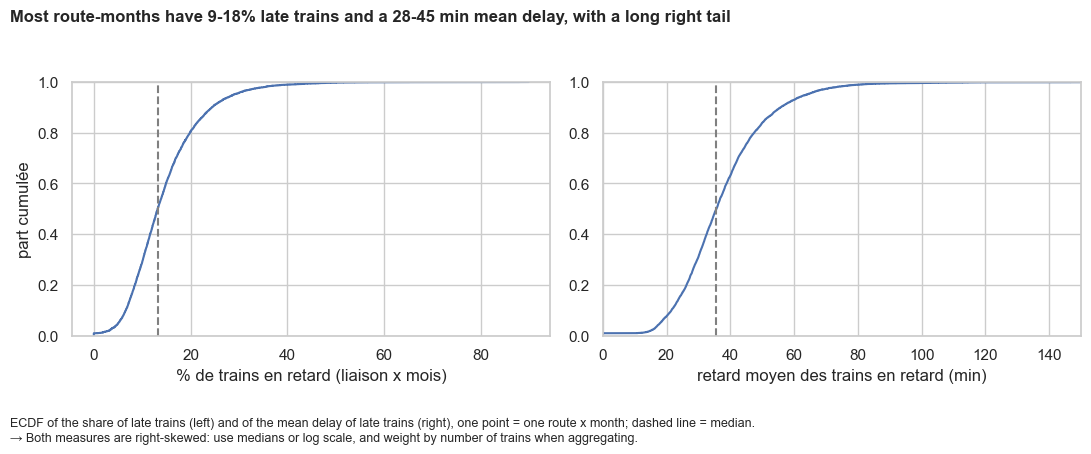

                       count       mean        std  min        25%        50%  \
taux_retard_%         8353.0  14.641196   7.852866  0.0   9.322034  13.207547   
retard_moyen_arrivee  8316.0  37.587994  15.251830  0.0  28.006823  35.657976   

                            75%         max  
taux_retard_%         18.333333   89.855072  
retard_moyen_arrivee  44.799662  299.600000  


In [39]:
# --- ajout groupe : distribution des 2 mesures (ECDF avant describe, comme demandé) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.ecdfplot(data=viz, x="taux_retard_%", ax=axes[0])
axes[0].set(xlabel="% de trains en retard (liaison x mois)", ylabel="part cumulée")
sns.ecdfplot(data=viz, x="retard_moyen_arrivee", ax=axes[1])
axes[1].set(xlabel="retard moyen des trains en retard (min)", xlim=(0, 150), ylabel="")
for ax, col in zip(axes, ["taux_retard_%", "retard_moyen_arrivee"]):
    ax.axvline(viz[col].median(), ls="--", c="grey")
show(fig, "Most route-months have 9-18% late trains and a 28-45 min mean delay, with a long right tail",
     "ECDF of the share of late trains (left) and of the mean delay of late trains (right), one point = one route x month; dashed line = median.",
     "Both measures are right-skewed: use medians or log scale, and weight by number of trains when aggregating.",
     "5_1")
print(viz[["taux_retard_%", "retard_moyen_arrivee"]].describe().T)

### 5.2 Bivariate

In [40]:
# TODO: one figure showing your key variable against 1–2 explanatory variables
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_2")

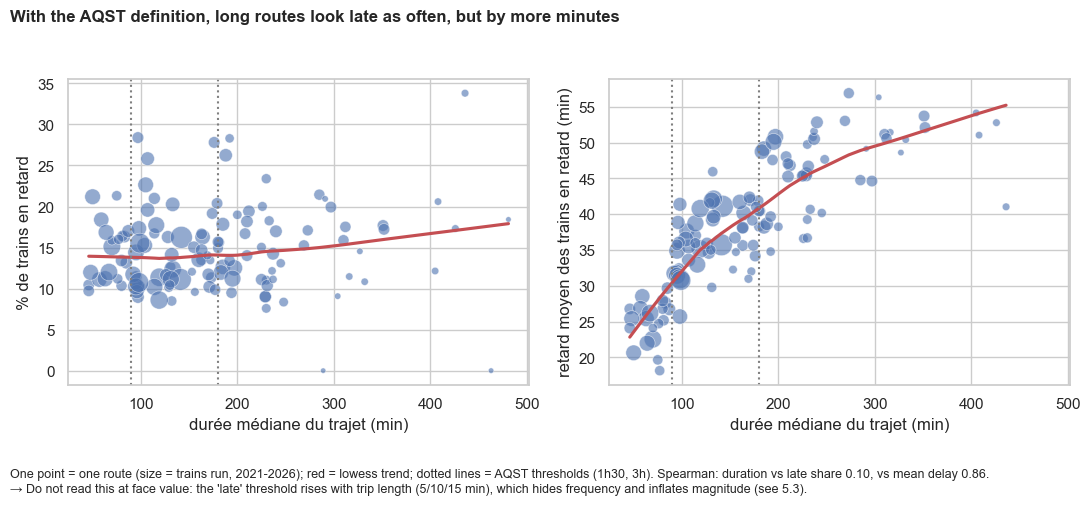

                  duree  taux_retard_%  retard_moyen_min
duree              1.00           0.10              0.86
taux_retard_%      0.10           1.00             -0.08
retard_moyen_min   0.86          -0.08              1.00


In [41]:
# --- ajout groupe : durée du trajet vs fréquence ET vs ampleur, 1 point = 1 liaison ---
# taille des points = nb de trains (une liaison à 30 trains/mois pèse moins qu'une à 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
for ax, y, lab in zip(axes, ["taux_retard_%", "retard_moyen_min"],
                      ["% de trains en retard", "retard moyen des trains en retard (min)"]):
    sns.scatterplot(data=liaisons, x="duree", y=y, size="circules", sizes=(15, 250),
                    alpha=0.6, legend=False, ax=ax)
    sns.regplot(data=liaisons, x="duree", y=y, scatter=False, lowess=True, color="C3", ax=ax)
    for s in (90, 180):
        ax.axvline(s, ls=":", c="grey")          # seuils AQST
    ax.set(xlabel="durée médiane du trajet (min)", ylabel=lab)

show(fig, "With the AQST definition, long routes look late as often, but by more minutes",
     "One point = one route (size = trains run, 2021-2026); red = lowess trend; dotted lines = AQST thresholds (1h30, 3h). Spearman: duration vs late share 0.10, vs mean delay 0.86.",
     "Do not read this at face value: the 'late' threshold rises with trip length (5/10/15 min), which hides frequency and inflates magnitude (see 5.3).",
     "5_2")

print(liaisons[["duree", "taux_retard_%", "retard_moyen_min"]].corr(method="spearman").round(2))

### 5.3 Multivariate

In [42]:
# TODO: one figure showing the correlation structure, or a breakdown by two categories
# fig, ax = plt.subplots(figsize=(8, 4))
# ...
# show(fig, "<title that states the finding>", "<what the figure shows>", "<what a modeller should do>", "5_3")

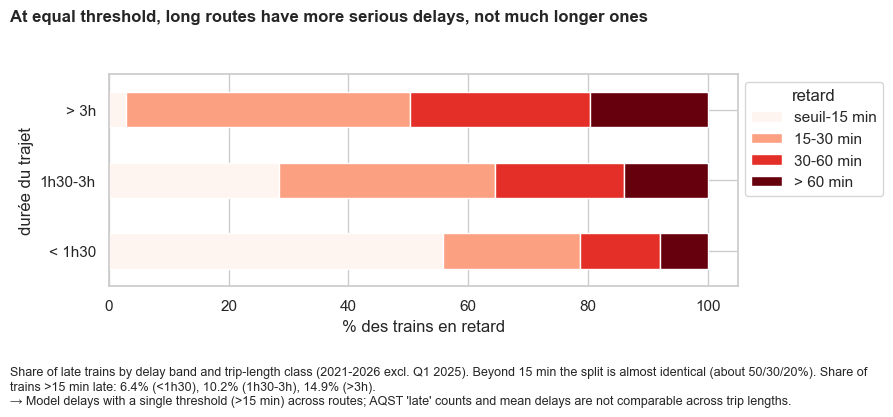

              seuil-15 min  15-30 min  30-60 min  > 60 min
classe_duree                                              
< 1h30                55.7       22.9       13.3       8.0
1h30-3h               28.4       36.2       21.5      14.0
> 3h                   2.9       47.4       30.0      19.7


In [43]:
# --- ajout groupe : parmi les trains en retard, quelle part en < 15 / 15-30 / 30-60 / > 60 min ? ---
# par classe de durée ; sans le T1 2025 (paliers en NaN, cf 4.2)
p = (viz.dropna(subset=paliers)
        .groupby("classe_duree", observed=True)[["nb_train_retard_arrivee"] + paliers].sum())
tranches = pd.DataFrame({
    "seuil-15 min": p["nb_train_retard_arrivee"] - p["nb_train_retard_sup_15"],
    "15-30 min": p["nb_train_retard_sup_15"] - p["nb_train_retard_sup_30"],
    "30-60 min": p["nb_train_retard_sup_30"] - p["nb_train_retard_sup_60"],
    "> 60 min": p["nb_train_retard_sup_60"],
})
tranches = 100 * tranches.div(tranches.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(9, 3.5))
tranches.plot(kind="barh", stacked=True, ax=ax, colormap="Reds")
ax.set(xlabel="% des trains en retard", ylabel="durée du trajet")
ax.legend(bbox_to_anchor=(1, 1), loc="upper left", title="retard")

show(fig, "At equal threshold, long routes have more serious delays, not much longer ones",
     "Share of late trains by delay band and trip-length class (2021-2026 excl. Q1 2025). Beyond 15 min the split is almost identical (about 50/30/20%). Share of trains >15 min late: 6.4% (<1h30), 10.2% (1h30-3h), 14.9% (>3h).",
     "Model delays with a single threshold (>15 min) across routes; AQST 'late' counts and mean delays are not comparable across trip lengths.",
     "5_3")

print(tranches.round(1))

In [44]:
# fréquence à règle égale : % de trains à +15 min (même seuil pour tous)
f = viz.dropna(subset=paliers).groupby("classe_duree", observed=True)[["nb_train_retard_sup_15", "circules"]].sum()
print((100 * f["nb_train_retard_sup_15"] / f["circules"]).round(1).rename("% trains > 15 min"))

classe_duree
< 1h30      6.4
1h30-3h    10.2
> 3h       14.9
Name: % trains > 15 min, dtype: float64


---
## 6 · Findings, what cannot be trusted, next steps

**Three findings**
1. **Delays are right-skewed** (Fig. 5.1): median 13% late trains, 36 min mean delay, tail up to 300 min. → Use medians, weight by trains.
2. **AQST view: long routes are late as often, but longer** (Fig. 5.2): Spearman 0.10 (frequency) vs 0.86 (magnitude). → Misleading: the late threshold rises with trip length.
3. **Same threshold (>15 min): long routes have more delays, not longer ones** (Fig. 5.3): 6.4% → 10.2% → 14.9% of trains >15 min late; severity split almost identical. → Use one threshold for all routes.

**What cannot be trusted**
- `nb_train_retard_arrivee`, `retard_moyen_arrivee` across routes of different length: AQST threshold varies (5/10/15 min).
- `nb_train_retard_sup_*` in Q1 2025: publication error, set to NaN.
- `retard_moyen_arrivee` on Barcelona, Madrid, Stuttgart: fake zeros + means on 1–2 trains.
- `service`: double publication Jul–Sep 2025, Barcelona relabelled in Oct 2025.
- Absent months (Italie, Zurich, Bordeaux–Tourcoing): suspensions, MNAR.

**Five testable hypotheses**
- **H1**: share >15 min ↑ with duration — National routes — Spearman + Kruskal–Wallis.
- **H2**: share >60 min (among >15) same across duration classes — all routes — chi-square.
- **H3**: International > National for share >15 min, routes >3h — Mann–Whitney.
- **H4**: more late trains in July–August — all route-months — Mann–Whitney.
- **H5**: cancellations ↑ ↔ late share ↑, same route-month — Spearman.

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [45]:
#clean_schema = None                  # TODO: pa.DataFrameSchema({...}, strict=True)

# --- ajout groupe : contrat des données propres (ce que reçoit le modélisateur) ---
# différences avec le schéma brut :
# - paliers en float + nullable=True : NaN sur T1 2025 (erreur de publication, cf 4.2)
# - retard_moyen_arrivee nullable=True : 37 faux zéros mis en NaN (cf 4.4)
# - clé unique SANS le service : les doublons National/International ont été retirés (cf 4.1)
# - paliers emboîtés : doit passer maintenant (NaN acceptés)

palier = lambda: pa.Column(float, pa.Check.ge(0), nullable=True)   # NaN justifiés ci-dessus
clean_schema = pa.DataFrameSchema(
    {
        "date": pa.Column(str, pa.Check.str_matches(r"^\d{4}-\d{2}$"), nullable=False),
        "service": pa.Column(str, pa.Check.isin(["National", "International"]), nullable=False),
        "gare_depart": pa.Column(str, pa.Check.str_length(min_value=1), nullable=False),
        "gare_arrivee": pa.Column(str, pa.Check.str_length(min_value=1), nullable=False),
        "duree_moyenne": pa.Column(int, pa.Check.in_range(1, 600), nullable=False),
        "nb_train_prevu": pa.Column(int, pa.Check.ge(0), nullable=False),
        "nb_annulation": pa.Column(int, pa.Check.ge(0), nullable=False),
        "nb_train_retard_arrivee": pa.Column(int, pa.Check.ge(0), nullable=False),
        "retard_moyen_arrivee": pa.Column(float, pa.Check.ge(0), nullable=True),
        "nb_train_retard_sup_15": palier(),
        "nb_train_retard_sup_30": palier(),
        "nb_train_retard_sup_60": palier(),
    },
    checks=[
        pa.Check(lambda d: d["nb_annulation"] <= d["nb_train_prevu"], name="annul_le_prevu"),
        pa.Check(lambda d: d["nb_train_retard_arrivee"] <= d["nb_train_prevu"] - d["nb_annulation"],
                 name="retard_le_circules"),
        # NaN acceptés (T1 2025), sinon les paliers doivent être emboîtés
        pa.Check(lambda d: d["nb_train_retard_sup_15"].isna()
                         | ((d["nb_train_retard_sup_60"] <= d["nb_train_retard_sup_30"])
                            & (d["nb_train_retard_sup_30"] <= d["nb_train_retard_sup_15"])),
                 name="paliers_emboites"),
        pa.Check(lambda d: d["nb_train_retard_sup_15"].isna()
                         | (d["nb_train_retard_sup_15"] <= d["nb_train_retard_arrivee"]),
                 name="sup15_le_retard"),
    ],
    unique=["date", "gare_depart", "gare_arrivee"],   # plus de doublon National/International
    strict=True,
)


if clean_schema is not None:
    clean_schema.validate(clean, lazy=True)
    print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

✅ clean data passes the contract
rows: 8353 · fingerprint: 380cf7b65fd6


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.